(10002, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10002 entries, 0 to 10001
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             10002 non-null  object 
 1   gender                  9992 non-null   object 
 2   age                     9997 non-null   float64
 3   country                 9998 non-null   object 
 4   city                    10002 non-null  object 
 5   customer_segment        9998 non-null   object 
 6   tenure_months           10002 non-null  int64  
 7   signup_channel          10002 non-null  object 
 8   contract_type           10002 non-null  object 
 9   monthly_logins          10002 non-null  int64  
 10  weekly_active_days      10002 non-null  int64  
 11  avg_session_time        10002 non-null  float64
 12  features_used           10002 non-null  int64  
 13  usage_growth_rate       10002 non-null  float64
 14  last_login_days_ago     10

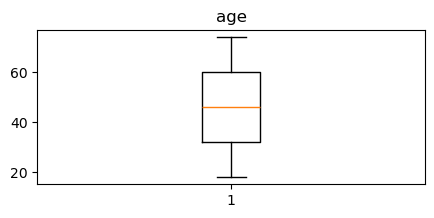

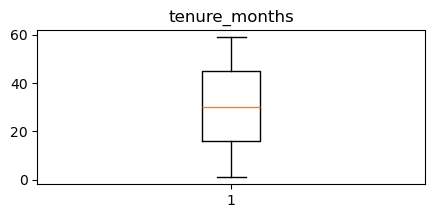

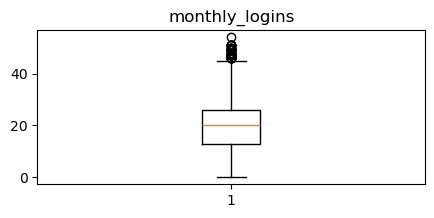

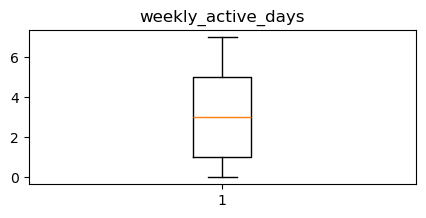

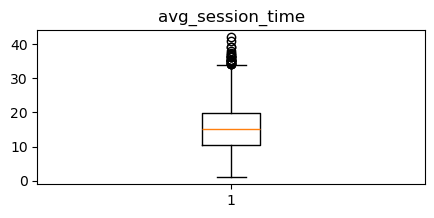

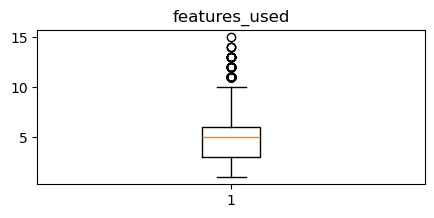

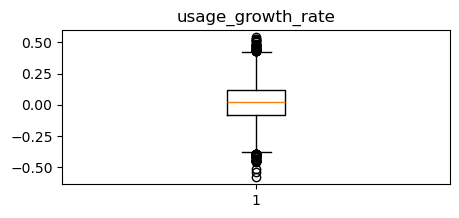

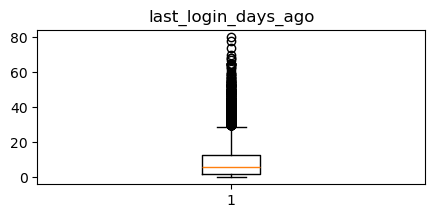

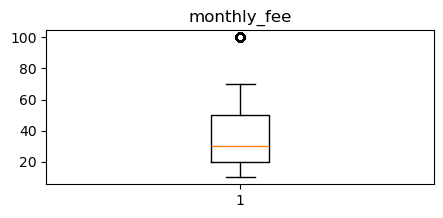

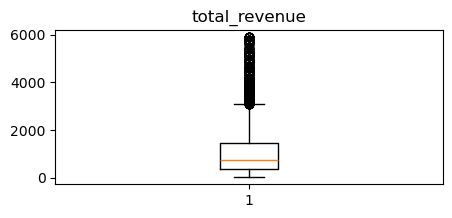

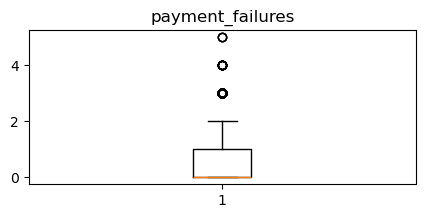

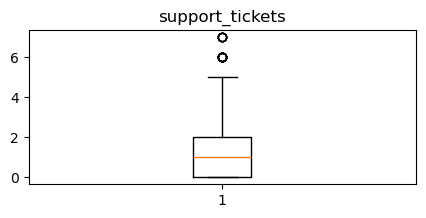

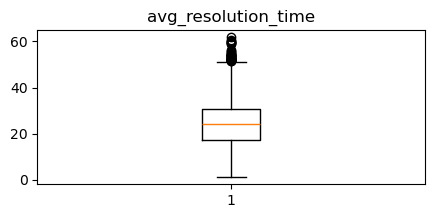

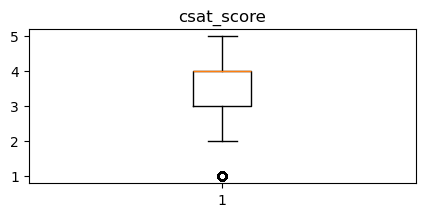

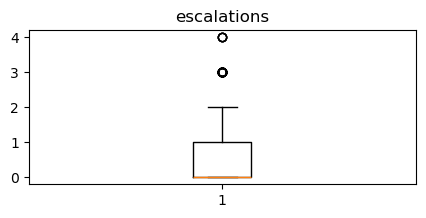

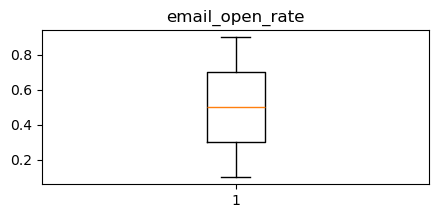

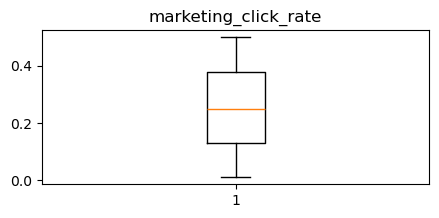

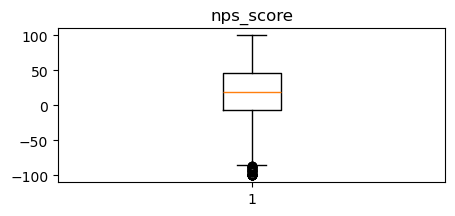

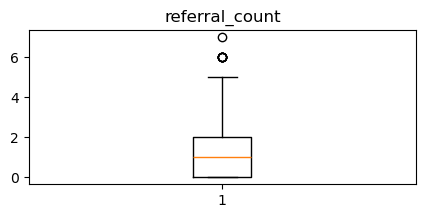

age                               0 outliers (0.00%)
tenure_months                     0 outliers (0.00%)
monthly_logins                   49 outliers (0.49%)
weekly_active_days                0 outliers (0.00%)
avg_session_time                 27 outliers (0.27%)
features_used                   121 outliers (1.21%)
usage_growth_rate                78 outliers (0.78%)
last_login_days_ago             471 outliers (4.71%)
monthly_fee                     513 outliers (5.13%)
total_revenue                   513 outliers (5.13%)
payment_failures                147 outliers (1.47%)
support_tickets                  18 outliers (0.18%)
avg_resolution_time              38 outliers (0.38%)
csat_score                      221 outliers (2.21%)
escalations                      43 outliers (0.43%)
email_open_rate                   0 outliers (0.00%)
marketing_click_rate              0 outliers (0.00%)
nps_score                        36 outliers (0.36%)
referral_count                    8 outliers (

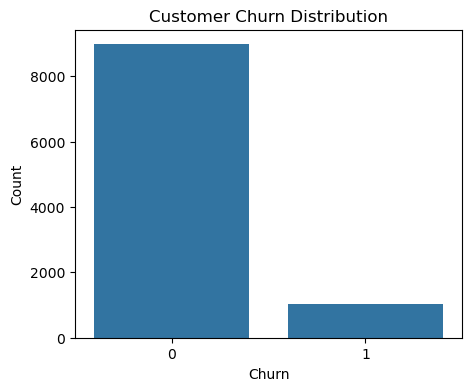

(10000, 31)
gender                    0
age                       0
country                   0
city                      0
customer_segment          0
tenure_months             0
signup_channel            0
contract_type             0
monthly_logins            0
weekly_active_days        0
avg_session_time          0
features_used             0
usage_growth_rate         0
last_login_days_ago       0
monthly_fee               0
total_revenue             0
payment_method            0
payment_failures          0
discount_applied          0
price_increase_last_3m    0
support_tickets           0
avg_resolution_time       0
complaint_type            0
csat_score                0
escalations               0
email_open_rate           0
marketing_click_rate      0
nps_score                 0
survey_response           0
referral_count            0
churn                     0
dtype: int64
0
FINAL DATASET VALIDATION
Dataset Shape: (10000, 31)

Missing Values
gender                    0
age      

In [1]:
#libraries 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns


#Loading the dataset

CustomerData_Df = pd.read_csv(
    "/Users/manesh/Library/CloudStorage/OneDrive-UniversityofPlymouth/Dissertation /Datset/customer_churn_business_dataset.csv"
)


#Confirm the dataset loaded successfully

CustomerData_Df.head()


#Explore and understand the imported dataset

print(CustomerData_Df.shape)

CustomerData_Df.info()


#Dataset summary statistics 

CustomerData_Df.describe()

CustomerData_Df.describe(include=['object','category'])



#Rename and Clean the dataset column names 

CustomerData_Df.columns = (
    CustomerData_Df.columns
    .str.lower()
    .str.strip()
    .str.replace(" ","_")
)



#Check the dataset column names

CustomerData_Df.columns



#Check missing values

CustomerData_Df.isnull().sum()



#=============================
# Handling Missing Values
#=============================


# Numerical variable

CustomerData_Df['age'] = CustomerData_Df['age'].fillna(
    CustomerData_Df['age'].median()
)


# Categorical variables

categorical_missing_cols = [
    'gender',
    'country',
    'customer_segment'
]


for col in categorical_missing_cols:
    
    CustomerData_Df[col] = CustomerData_Df[col].fillna(
        'unknown'
    )


# Complaint missing values

CustomerData_Df['complaint_type'] = (
    CustomerData_Df['complaint_type']
    .fillna('type_missing')
)



# Verify missing values

print("="*50)

print("Missing Values After Cleaning")

print(CustomerData_Df.isnull().sum())


print(
"\nTotal Missing Values:",
CustomerData_Df.isnull().sum().sum()
)



#=============================
# Check Impossible Values
#=============================


print("="*50)

print("Customers younger than 18")


print(
CustomerData_Df[
    CustomerData_Df["age"] < 18
]
)


print(
"Number of records:",
len(
CustomerData_Df[
CustomerData_Df["age"] < 18
]
)
)



#=============================
# Duplicate Removal
#=============================


print("="*50)

print("Duplicate Records")


duplicates = CustomerData_Df.duplicated().sum()


print(
"Duplicate rows:",
duplicates
)


CustomerData_Df.drop_duplicates(
    inplace=True
)


print(
"Rows removed:",
duplicates
)


print(
"Remaining duplicates:",
CustomerData_Df.duplicated().sum()
)



# Remove impossible age values

CustomerData_Df = CustomerData_Df[
    CustomerData_Df['age'] >= 18
]



#=============================
# Negative Value Check
#=============================


negative_fee = CustomerData_Df[
    CustomerData_Df["monthly_fee"] < 0
]


print("="*50)

print("Negative monthly fees:")

print(negative_fee)


print(
"Number of negative values:",
len(negative_fee)
)



# Remove impossible monthly fees

CustomerData_Df = CustomerData_Df[
    CustomerData_Df["monthly_fee"] >= 0
]



#=============================
# Remove Identifier Column
#=============================


CustomerData_Df.drop(
    columns=['customer_id'],
    inplace=True
)



print(CustomerData_Df.columns)



#=============================
# Categorical Cleaning
#=============================


cat_cols = CustomerData_Df.select_dtypes(
    include=['object']
).columns



# Check categories before cleaning

for col in cat_cols:
    
    print("="*50)
    
    print(col)
    
    print(CustomerData_Df[col].value_counts())



# Standardise categories

for col in cat_cols:
    
    CustomerData_Df[col] = (
        CustomerData_Df[col]
        .str.strip()
        .str.lower()
    )



# Convert categorical columns

for col in cat_cols:
    
    CustomerData_Df[col] = (
        CustomerData_Df[col]
        .astype('category')
    )



# Check categories after cleaning

print("="*50)

print("Categories After Standardisation")


for col in cat_cols:
    
    print("\n",col)
    
    print(CustomerData_Df[col].unique())



#=============================
# Data Type Conversion
#=============================


CustomerData_Df['age'] = (
    pd.to_numeric(
        CustomerData_Df['age']
        .astype('Int64')
    )
)



# Convert financial variables

CustomerData_Df['monthly_fee'] = (
    CustomerData_Df['monthly_fee']
    .astype(float)
)


CustomerData_Df['total_revenue'] = (
    CustomerData_Df['total_revenue']
    .astype(float)
)



print(
"Data Types:"
)

print(CustomerData_Df.dtypes)



#=============================
# Outlier Detection
#=============================


numerics = CustomerData_Df.select_dtypes(
    include=np.number
)



for col in numerics.columns:
    
    if col != 'churn':
        
        plt.figure(figsize=(5,2))
        
        plt.boxplot(
            CustomerData_Df[col]
        )
        
        plt.title(col)
        
        plt.show()



# IQR Method

numeric_cols = (
    CustomerData_Df
    .select_dtypes(include=np.number)
    .columns
    .drop('churn')
)



for col in numeric_cols:


    Q1 = CustomerData_Df[col].quantile(0.25)

    Q3 = CustomerData_Df[col].quantile(0.75)


    IQR = Q3-Q1


    lower = Q1 - 1.5*IQR

    upper = Q3 + 1.5*IQR



    outliers = CustomerData_Df[
        (CustomerData_Df[col] < lower) |
        (CustomerData_Df[col] > upper)
    ]



    percentage = (
        len(outliers) /
        len(CustomerData_Df)
        *100
    )



    print(
        f"{col:<30}"
        f"{len(outliers):>5} outliers "
        f"({percentage:.2f}%)"
    )



#=============================
# Class Balance Check
#=============================


print("="*50)

print("Class Distribution")


print(
CustomerData_Df['churn']
.value_counts()
)



print(
CustomerData_Df['churn']
.value_counts(normalize=True)
*100
)



plt.figure(figsize=(5,4))


sns.countplot(
    x='churn',
    data=CustomerData_Df
)


plt.title(
"Customer Churn Distribution"
)


plt.xlabel("Churn")

plt.ylabel("Count")


plt.show()



#=============================
# Save Clean Dataset
#=============================


CustomerData_Df.to_csv(
"customer_churn_cleaned.csv",
index=False
)



# Reload dataset

clean_df = pd.read_csv(
"customer_churn_cleaned.csv"
)



print(clean_df.shape)

print(clean_df.isnull().sum())

print(clean_df.duplicated().sum())



#=============================
# Final Validation
#=============================


print("="*60)

print("FINAL DATASET VALIDATION")

print("="*60)



print(
"Dataset Shape:",
CustomerData_Df.shape
)



print("\nMissing Values")

print(
CustomerData_Df.isnull().sum()
)



print(
"\nTotal Missing Values:",
CustomerData_Df.isnull().sum().sum()
)



print(
"\nDuplicate Rows:",
CustomerData_Df.duplicated().sum()
)



print("\nSummary Statistics")

print(
CustomerData_Df.describe(include='all').T
)



# Final summary for dissertation

print("="*60)

print("FINAL DATASET SUMMARY")

print("="*60)


print(
"Rows:",
CustomerData_Df.shape[0]
)


print(
"Columns:",
CustomerData_Df.shape[1]
)


print(
"Missing Values:",
CustomerData_Df.isnull().sum().sum()
)


print(
"Duplicate Rows:",
CustomerData_Df.duplicated().sum()
)


print(
"\nChurn Distribution:"
)


print(
CustomerData_Df['churn'].value_counts()
)



print("="*60)

print(
"DATA CLEANING COMPLETED SUCCESSFULLY"
)

print("="*60)